In [1]:
import glob
import yaml
import ml_collections
from tqdm import tqdm
from arch import arch_model
from scipy.stats import norm
from scipy.optimize import minimize
from scipy.stats.mstats import winsorize
from utils.utils import *
from utils.metric import *
from utils.eval_portfolio.summary import *
from utils.eval_portfolio.strategies import log_return_to_price
from utils.file_manager import LOCAL_BASE_DIRECTORY, quantDiffusionPath
from models.modernTCN_attention_v4 import ModernTCN
from torch.utils.data import DataLoader, TensorDataset
from modules.diffusion import TimeSeriesGaussianDiffusion, generate_linear_schedule, generate_cosine_schedule


file_manager = quantDiffusionPath()
gc.collect()

0

In [2]:
# import yfinance as yf
# import pandas as pd

# # 1. 티커 심볼 설정 (순서 고정)
# # DJI(^DJI), IXIC(^IXIC), JPM(JPM), HSI(^HSI), Gold(GC=F), WTI(CL=F)
# ticker_map = {
#     '^DJI': 'DJI',
#     '^IXIC': 'IXIC',
#     '^HSI': 'HSI',
#     'GC=F': 'Gold',
#     'CL=F': 'WTI'
# }
# tickers = list(ticker_map.keys())

# # 2. 데이터 다운로드 (2001년 1월 1일 ~ 2024년 12월 31일)
# start_date = "2001-01-01"
# end_date = "2025-01-01"

# print(f"{start_date}부터 {end_date} 전까지 데이터를 불러오는 중...")
# raw_data = yf.download(tickers, start=start_date, end=end_date)['Close']

# # 3. 요청하신 순서대로 컬럼 재정렬 및 이름 변경
# # 데이터프레임에서 티커 순서를 보장하기 위해 리스트를 다시 지정합니다.
# df = raw_data[tickers]
# df.columns = [ticker_map[t] for t in tickers]
# df = df.dropna()

# df_JP = pd.read_csv(f"./data/sp500.csv", index_col=0)
# df_JP.index = pd.to_datetime(df_JP.index)
# df_JP = df_JP.loc[df.index, 'JPM']

# df = pd.concat([df, df_JP], axis=1)
# feature_names = ['DJI', 'IXIC', 'JPM', 'HSI', 'Gold', 'WTI']
# df = df[feature_names]
# df.columns = ['DJI', 'NASDAQ', 'JPM', 'HSI', 'GOLD', 'WTI_OIL']

In [21]:
from sklearn.preprocessing import QuantileTransformer

def ensure_2d(x):
    x = np.asarray(x, dtype=np.float64)
    if x.ndim == 1:
        x = x[:, None]
    return x


class GARCH11:
    """
    Univariate GARCH(1,1)
        r_t = sigma_t * z_t
        sigma_t^2 = omega + alpha * r_{t-1}^2 + beta * sigma_{t-1}^2
    """

    def __init__(self):
        self.params_ = None
        self.sigma2_ = None
        self.sigma_ = None
        self.z_ = None
        self.llf_ = None

    @staticmethod
    def _variance_recursion(params, r):
        omega, alpha, beta = params
        T = len(r)

        sigma2 = np.zeros(T, dtype=np.float64)

        # 초기값: sample variance
        sigma2[0] = max(np.var(r), 1e-8)

        for t in range(1, T):
            sigma2[t] = omega + alpha * (r[t - 1] ** 2) + beta * sigma2[t - 1]
            if sigma2[t] < 1e-12:
                sigma2[t] = 1e-12

        return sigma2

    @staticmethod
    def _neg_loglik(params, r):
        omega, alpha, beta = params

        # 안정성 제약
        if omega <= 0 or alpha < 0 or beta < 0 or (alpha + beta) >= 0.999:
            return 1e12

        sigma2 = GARCH11._variance_recursion(params, r)

        ll = -0.5 * np.sum(
            np.log(2 * np.pi) + np.log(sigma2) + (r ** 2) / sigma2
        )
        return -ll

    def fit(self, r):
        r = np.asarray(r, dtype=np.float64).flatten()

        var_r = np.var(r) + 1e-8
        x0 = np.array([0.01 * var_r, 0.05, 0.90], dtype=np.float64)

        bounds = [
            (1e-12, None),  # omega
            (1e-8, 1.0),    # alpha
            (1e-8, 1.0),    # beta
        ]

        constraints = [
            {"type": "ineq", "fun": lambda x: 0.999 - x[1] - x[2]}
        ]

        res = minimize(
            self._neg_loglik,
            x0,
            args=(r,),
            method="SLSQP",
            bounds=bounds,
            constraints=constraints,
            options={"maxiter": 500, "ftol": 1e-9, "disp": False},
        )

        if not res.success:
            # fallback
            params = np.array([0.01 * var_r, 0.05, 0.90], dtype=np.float64)
        else:
            params = res.x

        sigma2 = self._variance_recursion(params, r)
        sigma = np.sqrt(np.clip(sigma2, 1e-12, None))
        z = r / sigma

        self.params_ = params
        self.sigma2_ = sigma2
        self.sigma_ = sigma
        self.z_ = z
        self.llf_ = -self._neg_loglik(params, r)

        return self


class DCCGARCH11:
    """
    DCC-GARCH(1,1)

    Step 1. 각 자산별 GARCH(1,1) 적합 -> sigma_t, z_t
    Step 2. standardized residual z_t 로 DCC(1,1) 적합
    Step 3. 필요시 R_t, H_t 계산

    네가 원하는 conditional volatility는 sigma_ 에 저장됨
    """

    def __init__(self):
        self.univariate_models_ = []
        self.garch_params_ = None
        self.dcc_params_ = None  # (a, b)

        self.Z_ = None
        self.sigma_ = None
        self.Qbar_ = None
        self.Q_ = None
        self.R_ = None
        self.H_ = None

        self.T_ = None
        self.N_ = None

    @staticmethod
    def _compute_QRt(Z, a, b):
        T, N = Z.shape

        # unconditional covariance of standardized residuals
        Qbar = np.cov(Z.T, bias=True)
        if np.ndim(Qbar) == 0:
            Qbar = np.array([[Qbar]], dtype=np.float64)

        Qbar = 0.5 * (Qbar + Qbar.T)
        Qbar += 1e-8 * np.eye(N)

        Q = np.zeros((T, N, N), dtype=np.float64)
        R = np.zeros((T, N, N), dtype=np.float64)

        Q[0] = Qbar.copy()

        d = np.sqrt(np.clip(np.diag(Q[0]), 1e-12, None))
        D_inv = np.diag(1.0 / d)
        R[0] = D_inv @ Q[0] @ D_inv
        R[0] = 0.5 * (R[0] + R[0].T)
        R[0] += 1e-10 * np.eye(N)

        for t in range(1, T):
            z_prev = Z[t - 1]
            outer = np.outer(z_prev, z_prev)

            Q[t] = (1.0 - a - b) * Qbar + a * outer + b * Q[t - 1]
            Q[t] = 0.5 * (Q[t] + Q[t].T)

            d = np.sqrt(np.clip(np.diag(Q[t]), 1e-12, None))
            D_inv = np.diag(1.0 / d)
            R[t] = D_inv @ Q[t] @ D_inv
            R[t] = 0.5 * (R[t] + R[t].T)
            R[t] += 1e-10 * np.eye(N)

        return Qbar, Q, R

    @staticmethod
    def _dcc_neg_loglik(params, Z):
        a, b = params

        if a < 0 or b < 0 or (a + b) >= 0.999:
            return 1e12

        T, N = Z.shape
        _, _, R = DCCGARCH11._compute_QRt(Z, a, b)

        ll = 0.0
        const = N * np.log(2 * np.pi)

        for t in range(T):
            Rt = R[t]

            sign, logdet = np.linalg.slogdet(Rt)
            if sign <= 0:
                return 1e12

            try:
                invRt = np.linalg.inv(Rt)
            except np.linalg.LinAlgError:
                return 1e12

            zt = Z[t]
            ll_t = -0.5 * (const + logdet + zt @ invRt @ zt)
            ll += ll_t

        return -ll

    def fit(self, X):
        X = ensure_2d(X)
        T, N = X.shape
        self.T_ = T
        self.N_ = N

        # 1) 각 자산별 GARCH(1,1)
        sigma = np.zeros((T, N), dtype=np.float64)
        Z = np.zeros((T, N), dtype=np.float64)
        garch_params = np.zeros((N, 3), dtype=np.float64)
        models = []

        # 평균 제거
        X_centered = X - np.mean(X, axis=0, keepdims=True)

        for i in range(N):
            model = GARCH11().fit(X_centered[:, i])
            sigma[:, i] = model.sigma_
            Z[:, i] = model.z_
            garch_params[i] = model.params_
            models.append(model)

        # standardized residual 중심화
        Z = Z - np.mean(Z, axis=0, keepdims=True)

        # 2) DCC fit
        x0 = np.array([0.02, 0.95], dtype=np.float64)
        bounds = [(1e-8, 0.999), (1e-8, 0.999)]
        constraints = [
            {"type": "ineq", "fun": lambda x: 0.999 - x[0] - x[1]}
        ]

        res = minimize(
            self._dcc_neg_loglik,
            x0,
            args=(Z,),
            method="SLSQP",
            bounds=bounds,
            constraints=constraints,
            options={"maxiter": 500, "ftol": 1e-9, "disp": False},
        )

        if not res.success:
            a, b = 0.02, 0.95
        else:
            a, b = res.x

        Qbar, Q, R = self._compute_QRt(Z, a, b)

        # 3) H_t = D_t R_t D_t
        H = np.zeros((T, N, N), dtype=np.float64)
        for t in range(T):
            Dt = np.diag(sigma[t])
            H[t] = Dt @ R[t] @ Dt
            H[t] = 0.5 * (H[t] + H[t].T)

        self.univariate_models_ = models
        self.garch_params_ = garch_params
        self.dcc_params_ = np.array([a, b], dtype=np.float64)

        self.Z_ = Z
        self.sigma_ = sigma
        self.Qbar_ = Qbar
        self.Q_ = Q
        self.R_ = R
        self.H_ = H

        return self

    def conditional_volatility(self):
        if self.sigma_ is None:
            raise RuntimeError("먼저 fit()을 호출하세요.")
        return self.sigma_

    def conditional_covariance(self):
        if self.H_ is None:
            raise RuntimeError("먼저 fit()을 호출하세요.")
        return self.H_

    def conditional_correlation(self):
        if self.R_ is None:
            raise RuntimeError("먼저 fit()을 호출하세요.")
        return self.R_

    def conditional_volatility_df(self, column_names=None):
        if self.sigma_ is None:
            raise RuntimeError("먼저 fit()을 호출하세요.")

        N = self.sigma_.shape[1]
        if column_names is None:
            column_names = [f"asset_{i+1}_vol" for i in range(N)]

        return pd.DataFrame(self.sigma_, columns=column_names)

# Preprocessing

In [22]:
def fit_transform_garch_12d(train_data):
    """
    Train 데이터를 GARCH로 분해하여 12차원(잔차 6 + 로그변동성 6)으로 만듭니다.

    Args:
        train_data: (T, 6) 형태의 원본 6차원 로그 수익률 (Numpy Array)
    Returns:
        train_12d: (T, 12) 형태의 정규화된 12차원 데이터
        garch_models: 학습된 6개의 GARCH 모델 객체 리스트 (Test 시 사용)
        scalers_Z: 잔차(Z)에 피팅된 스케일러들 (SA, LW, SS)
        scalers_V: 로그변동성(V)에 피팅된 스케일러들 (SA, LW, SS)
    """
    T, C = train_data.shape
    Z_list = []  # 잔차 저장용
    V_list = []  # 로그 변동성 저장용
    garch_models = []

    print("⏳ 6개 자산에 대해 GARCH(1,1) 피팅 및 분해 진행 중...")

    # 1. 자산별 GARCH 분해
    for i in range(C):
        asset_returns = train_data[:, i]

        # GARCH(1,1) 모델 정의 (평균 방정식은 Constant 0으로 두고 분산만 추정)
        # rescale=False로 두어 스케일 경고 방지
        am = arch_model(
            asset_returns, vol="Garch", p=1, q=1, mean="Zero", rescale=True, dist="ged"
        )
        res = am.fit(disp="off")  # 학습 진행 (로그 출력 끄기)
        # 2. 최적화 알고리즘(Optimizer) 설정 강화
        garch_models.append(res)

        # 조건부 변동성 추출 (sigma_t)
        sigma_t = res.conditional_volatility

        # 1-1. 잔차 공간 (Z_t = X_t / sigma_t)
        Z_t = asset_returns / sigma_t

        # 1-2. 로그 변동성 공간 (V_t = ln(sigma_t))
        # 변동성이 0에 가까울 때 로그가 무한대로 가는 것을 막기 위해 미세값(eps) 추가
        eps = 1e-8
        V_t = np.log(sigma_t + eps)

        Z_list.append(Z_t.reshape(-1, 1))
        V_list.append(V_t.reshape(-1, 1))

    # (T, 6) 형태로 병합
    Z_raw = np.hstack(Z_list)
    V_raw = np.hstack(V_list)

    print("✅ GARCH 분해 완료. 듀얼 정규화(SA -> LW -> SS) 적용 중...")
    raw_12d = np.concatenate([Z_raw, V_raw], axis=1)
    scaled_12d, scalers = scaling(raw_12d)

    return scaled_12d, scalers


def inverse_garch_12d_to_6d(generated_12d, scalers):
    """
    Diffusion이 생성한 12차원 데이터를 원본 6차원 수익률로 완벽하게 복원합니다.

    Args:
        generated_12d: (B, 12, T) 또는 (B, T, 12) 형태의 텐서/배열
        scalers_Z: Train에서 학습한 잔차(Z) 스케일러 리스트
        scalers_V: Train에서 학습한 로그변동성(V) 스케일러 리스트
    Returns:
        X_reconstructed: 복원된 (B, 6, T) 또는 (B, T, 6) 형태의 원본 6차원 텐서
    """
    # 3. 12차원 반갈죽 (앞 6: 잔차 Z, 뒤 6: 로그변동성 V)
    inv_12d = inverse_scaling(generated_12d.transpose(1, 2), scalers)

    Z_inv = inv_12d[:, :6, :]
    V_inv = inv_12d[:, 6:, :]

    # 5. 변동성 복구 (로그 해제)
    # 💡 방어 로직: 학습 초반 모델이 미친 값을 뱉을 때 exp가 우주로 가는 것 방지 (max 값을 약 10 내외로 제한)
    V_inv = np.clip(V_inv, a_min=-20.0, a_max=10.0)
    sigma_t = np.exp(V_inv)

    # 6. 최종 6차원 SDE 합성 (Z * sigma)
    # 평온했던 Z 노이즈에 변동성 스파이크를 때려 박아 현실 세계의 폭락/폭등을 구현
    X_reconstructed = Z_inv * sigma_t

    return X_reconstructed
    # return np.transpose(X_reconstructed, (0, 2, 1))

In [25]:


def fit_transform_garch_12d(train_data, eps=1e-8):
    """
    train 데이터를 DCC-GARCH(1,1)로 분해하여
    12차원 특징 [Z(잔차 6), V(로그변동성 6)] 을 생성한 뒤 정규화합니다.

    Args:
        train_data: shape (T, C) 의 수익률 데이터
        eps: 수치 안정성을 위한 작은 값

    Returns:
        scaled_12d: shape (T, 2C) 의 정규화된 12차원 데이터
        model: 학습된 DCCGARCH11 모델
        scalers: scaling()에서 반환된 스케일러 정보
    """
    train_data = np.asarray(train_data, dtype=np.float64)

    if train_data.ndim != 2:
        raise ValueError("train_data must be a 2D array of shape (T, C)")

    T, C = train_data.shape

    print(f"⏳ {C}개 자산에 대해 DCC-GARCH(1,1) 피팅 및 분해 진행 중...")

    # 1) DCC-GARCH 적합
    model = DCCGARCH11().fit(train_data)

    # 2) 조건부 변동성 추출
    cond_vol = model.conditional_volatility()  # shape: (T, C)
    cond_vol = np.asarray(cond_vol, dtype=np.float64)
    cond_vol = np.clip(cond_vol, eps, None)

    # 3) 잔차 공간 Z = X / sigma
    Z_raw = train_data / cond_vol
    eps = 1e-8
    # 4) 로그 변동성 공간 V = log(sigma)
    V_raw = np.log(cond_vol+eps)

    # 1. 잔차(Z) 공간: 기존 scaling 함수 적용 (이때 scalers 리스트가 생성됨)
    Z_scaled, scalers = scaling(Z_raw)
    
    # 2. 로그 변동성(V) 공간: 말씀하신 가우시안 변환기 적용
    # 데이터 길이에 맞춰 n_quantiles를 자동 조절하여 에러 방지
    v_transformer = QuantileTransformer(output_distribution='normal', n_quantiles=max(100, min(1000, T)), random_state=42)
    V_scaled = v_transformer.fit_transform(V_raw)

    # 3. 12차원 병합
    scaled_12d = np.concatenate([Z_scaled, V_scaled], axis=1)

    # 4. 리스트 마지막에 추가 (입출력 구조 완벽 유지)
    scalers.append(v_transformer)

    return scaled_12d, scalers

In [26]:
# def fit_transform_garch_12d(train_data):
#     """
#     Train 데이터를 GARCH로 분해하여 12차원으로 만듭니다.
#     기존 인터페이스를 유지하여 scalers 리스트 하나만 반환합니다.
#     """
#     T, C = train_data.shape
#     Z_list = []
#     V_list = []

#     print("⏳ 6개 자산에 대해 GARCH(1,1) 피팅 및 분해 진행 중...")

#     for i in range(C):
#         asset_returns = train_data[:, i]

#         am = arch_model(
#             asset_returns, vol="Garch", p=1, q=1, mean="Zero", rescale=True, dist="ged"
#         )
#         with warnings.catch_warnings():
#             warnings.simplefilter("ignore")
#             res = am.fit(disp="off", show_warning=False)

#         sigma_t = res.conditional_volatility

#         Z_t = asset_returns / sigma_t
#         eps = 1e-8
#         V_t = np.log(sigma_t + eps)

#         Z_list.append(Z_t.reshape(-1, 1))
#         V_list.append(V_t.reshape(-1, 1))

#     Z_raw = np.hstack(Z_list)
#     V_raw = np.hstack(V_list)

#     print("✅ GARCH 분해 완료. Z와 V에 각각 독립적인 스케일링 적용 중...")
    
#     # 1. 잔차(Z) 공간: 기존 scaling 함수 적용 (이때 scalers 리스트가 생성됨)
#     Z_scaled, scalers = scaling(Z_raw)
    
#     # 2. 로그 변동성(V) 공간: 말씀하신 가우시안 변환기 적용
#     # 데이터 길이에 맞춰 n_quantiles를 자동 조절하여 에러 방지
#     v_transformer = QuantileTransformer(output_distribution='normal', n_quantiles=max(100, min(1000, T)), random_state=42)
#     V_scaled = v_transformer.fit_transform(V_raw)

#     # 3. 12차원 병합
#     scaled_12d = np.concatenate([Z_scaled, V_scaled], axis=1)

#     # 4. 리스트 마지막에 추가 (입출력 구조 완벽 유지)
#     scalers.append(v_transformer)

#     return scaled_12d, scalers


def inverse_garch_12d_to_6d(generated_12d, scalers):
    """
    Diffusion이 생성한 12차원 데이터를 원본 6차원 수익률로 복원합니다.
    """
    # 1. PyTorch 텐서가 들어오면 NumPy로 안전하게 변환
    if isinstance(generated_12d, torch.Tensor):
        generated_12d = generated_12d.detach().cpu().numpy()

    scalers_copy = scalers.copy()
    
    # 마지막 요소 분리 (V에 적용했던 가우시안 변환기)
    v_transformer = scalers_copy.pop()
    
    # 차원 방어 로직 ((B, 12, T) 구조로 통일)
    if len(generated_12d.shape) == 3 and generated_12d.shape[2] == 12:
        generated_12d = generated_12d.transpose(0, 2, 1)
        
    expanded = False
    if len(generated_12d.shape) == 2:
        if generated_12d.shape[1] == 12:
            generated_12d = generated_12d.T
        generated_12d = np.expand_dims(generated_12d, axis=0)
        expanded = True

    # Z와 V 분리 (둘 다 현재 NumPy array 상태)
    Z_generated = generated_12d[:, :6, :]
    V_generated = generated_12d[:, 6:, :]

    # ==========================================
    # 💡 핵심 수정: utils.py가 텐서를 요구하므로 잠시 torch.tensor로 감싸서 넘깁니다!
    # ==========================================
    Z_inv = inverse_scaling(torch.tensor(Z_generated), scalers_copy)

    # 3. V 역변환 (scikit-learn)
    B, C, T_seq = V_generated.shape
    V_generated_2d = V_generated.transpose(0, 2, 1).reshape(-1, C)
    
    V_inv_2d = v_transformer.inverse_transform(V_generated_2d)
    
    V_inv = V_inv_2d.reshape(B, T_seq, C).transpose(0, 2, 1)

    # 4. 변동성 복구 (로그 해제 및 스파이크 방어)
    V_inv = np.clip(V_inv, a_min=-20.0, a_max=10.0)
    sigma_t = np.exp(V_inv)

    # 5. SDE 합성 (Z * sigma)
    X_reconstructed = Z_inv * sigma_t 

    # 6. 원래 차원으로 원복
    if expanded:
        X_reconstructed = np.squeeze(X_reconstructed, axis=0)

    return X_reconstructed

In [27]:
# --- [0. 준비 단계] ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
seq_len = 256

# 데이터 로드
df = pd.read_csv(f"./data/indices2.csv")
df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m-%d')
df.set_index('Date', inplace=True)
df = df.apply(pd.to_numeric).astype(float)

log_returns = np.log1p(df.pct_change()).dropna().values
init_price_raw = np.array(df)[:-1, :]

# --- [1. Early Split (시간 순 분할)] ---
total_len = len(log_returns)
train_size = int(0.7 * total_len)

train_raw = log_returns[:train_size]
test_raw = log_returns[train_size:] # Test는 원본 6차원 그대로 대기

train_init_raw = init_price_raw[:train_size]
test_init_raw = init_price_raw[train_size:]

# --- [2. GARCH 12차원 전처리 (Train ONLY)] ---
# Train만 GARCH로 12차원 분해 및 스케일링 수행
train_12d, scalers = fit_transform_garch_12d(log_returns)


train_12d = train_12d[:train_size]

# --- [3. Windowing (시퀀스 쪼개기)] ---
# Train은 12차원 윈도우 생성
train_windowed = torch.from_numpy(rolling_window(train_12d, seq_len)).float()
train_init_windowed = torch.from_numpy(train_init_raw[:-(seq_len-1)]).float().unsqueeze(1)

test_windowed = torch.from_numpy(rolling_window(test_raw, seq_len)).float()
test_init_windowed = torch.from_numpy(test_init_raw[:-(seq_len-1)]).float().unsqueeze(1)

# (B, T, C) -> (B, C, T) 축 변환
training_data = train_windowed.clone().detach() # (B, 256, 12)
test_data = test_windowed.clone().detach()  # (B, 256, 6)

training_set = TensorDataset(training_data)
test_set = TensorDataset(test_data)

train_dl = DataLoader(training_set, batch_size=256, shuffle=False)
test_dl = DataLoader(test_set, batch_size=256, shuffle=False)

print("\n🚀 데이터 준비 완료!")
print(f"Train DataLoader 배치 크기: {next(iter(train_dl))[0].shape}")
print(f"Test DataLoader 배치 크기: {next(iter(test_dl))[0].shape}")

c:\Users\asas4\AppData\Local\miniconda3\envs\research\lib\site-packages\pandas\core\internals\blocks.py:395: RuntimeWarning: invalid value encountered in log1p
  result = func(self.values, **kwargs)


⏳ 6개 자산에 대해 DCC-GARCH(1,1) 피팅 및 분해 진행 중...


c:\Users\asas4\AppData\Local\miniconda3\envs\research\lib\site-packages\scipy\optimize\_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
c:\Users\asas4\AppData\Local\miniconda3\envs\research\lib\site-packages\scipy\optimize\_slsqp_py.py:441: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  g = append(wrapped_grad(x), 0.0)
c:\Users\asas4\AppData\Local\miniconda3\envs\research\lib\site-packages\scipy\optimize\_slsqp_py.py:501: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  a_ieq = vstack([con['jac'](x, *con['args'])
c:\Users\asas4\OneDrive\Dokumen\GitHub\quantDiffusion\utils\gaussianize.py:165: UserWarning: Warning: No convergence after 150 iterations. Increase max_iter.
  warnings.warn("Warning: No convergence after %d iterations. Increase max_iter." % max_iter)



🚀 데이터 준비 완료!
Train DataLoader 배치 크기: torch.Size([256, 256, 12])
Test DataLoader 배치 크기: torch.Size([256, 256, 6])


c:\Users\asas4\OneDrive\Dokumen\GitHub\quantDiffusion\utils\gaussianize.py:165: UserWarning: Warning: No convergence after 150 iterations. Increase max_iter.
  warnings.warn("Warning: No convergence after %d iterations. Increase max_iter." % max_iter)


In [29]:
train_12d[0]

array([ 4.39689566,  4.25155105,  3.22863205, -1.09035286, -0.18971302,
        1.7943653 , -5.19933758,  1.13209291,  1.20369145,  1.22392311,
        1.26108905, -5.19933758])

Asset 0 - KS Statistic ($D$): 0.022572
p = 0.0329


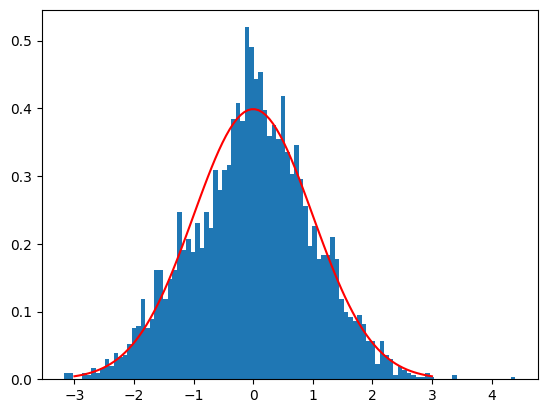

Asset 1 - KS Statistic ($D$): 0.026279
p = 0.0076


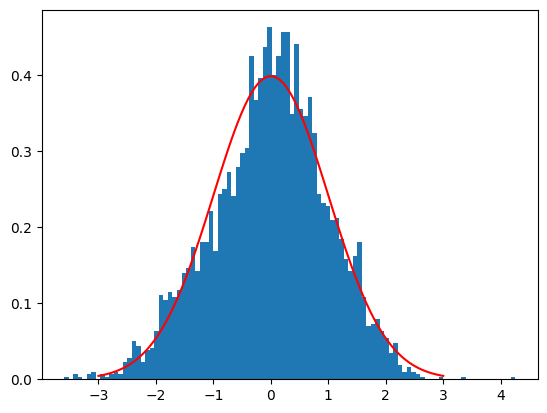

Asset 2 - KS Statistic ($D$): 0.011055
p = 0.7057


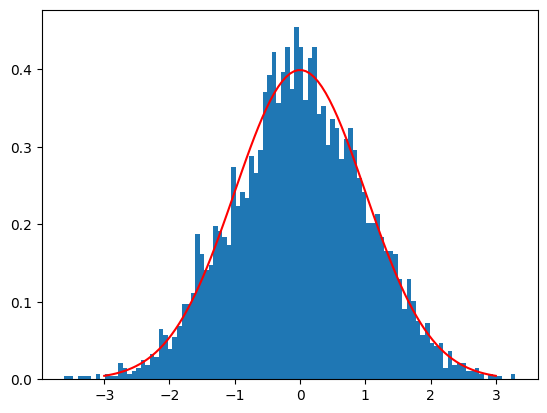

Asset 3 - KS Statistic ($D$): 0.031707
p < 0.001


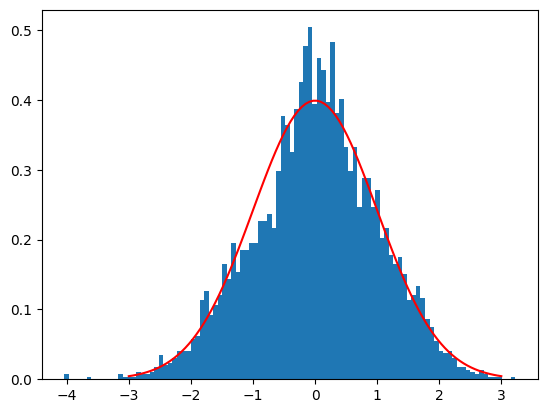

Asset 4 - KS Statistic ($D$): 0.011608
p = 0.6468


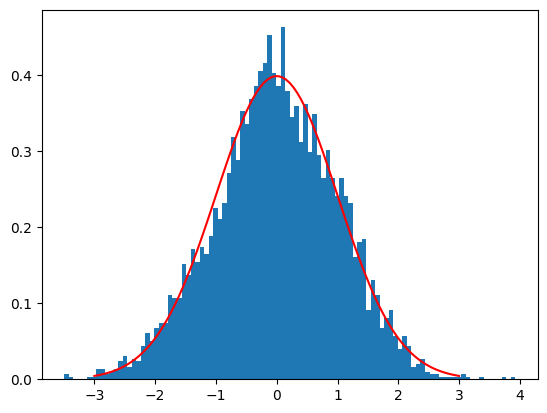

Asset 5 - KS Statistic ($D$): 0.009415
p = 0.8652


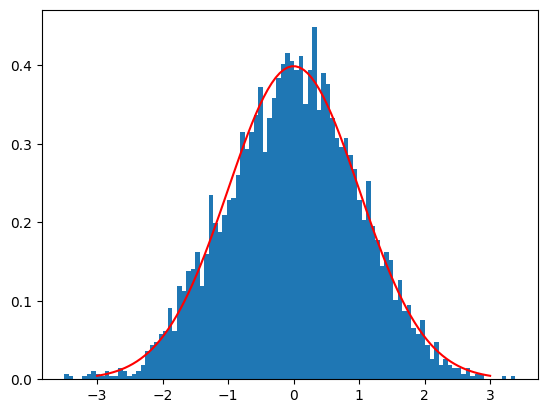

Asset 6 - KS Statistic ($D$): 0.006705
p = 0.9931


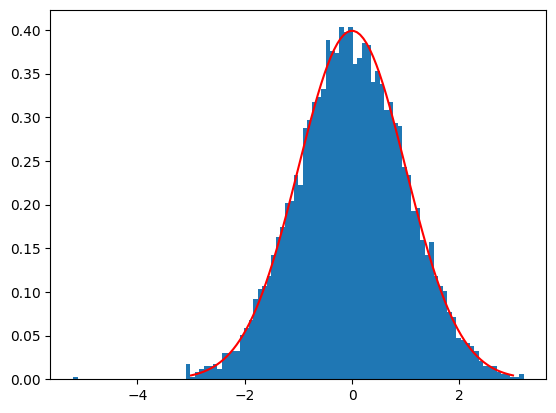

Asset 7 - KS Statistic ($D$): 0.028718
p = 0.0026


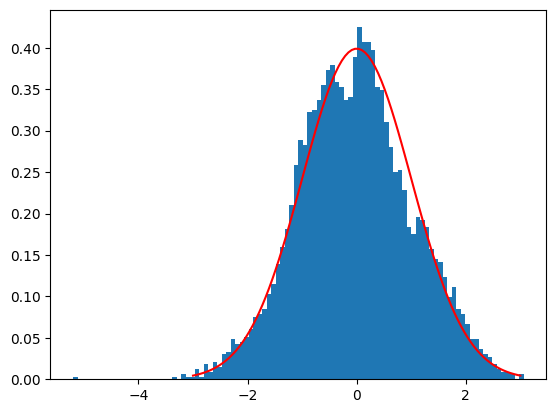

Asset 8 - KS Statistic ($D$): 0.053811
p < 0.001


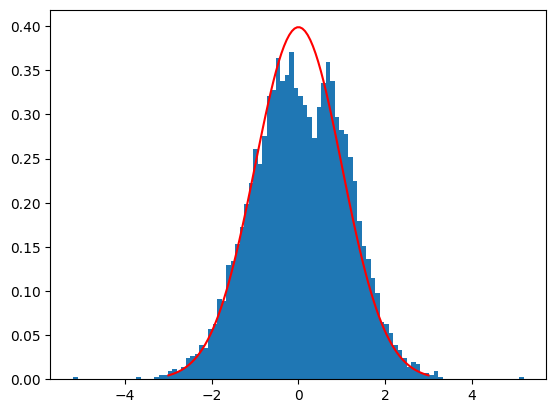

Asset 9 - KS Statistic ($D$): 0.063806
p < 0.001


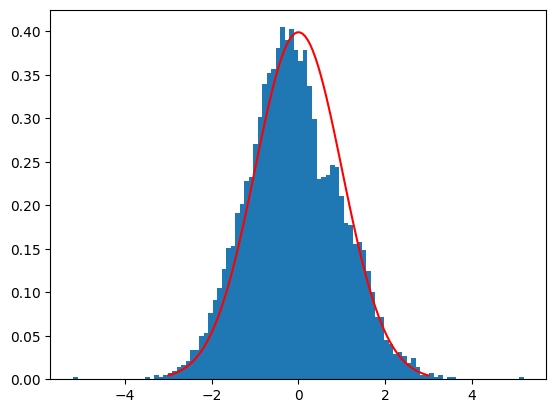

Asset 10 - KS Statistic ($D$): 0.066400
p < 0.001


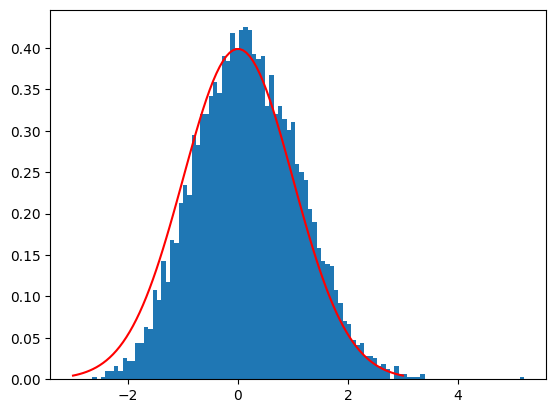

Asset 11 - KS Statistic ($D$): 0.006922
p = 0.9899


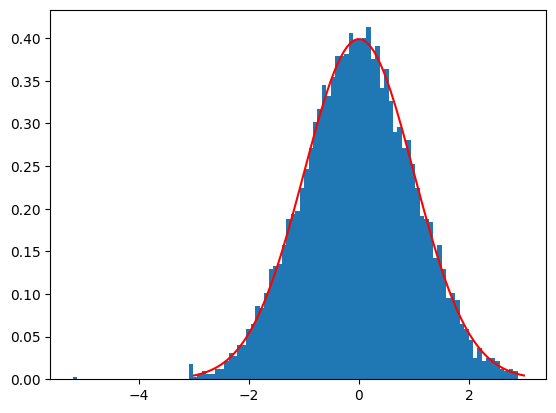

In [30]:
import matplotlib.pyplot as plt
from scipy.stats import kstest

for i in range(12):
    data =  train_12d[:,i]
    # data = winsorize(data, limits=[0.01, 0.01])
    ks_stat, p_val = kstest(data, 'norm')

    # 학술적 표기법: p-value가 매우 작을 경우 < 0.001로 표기
    p_text = f"p < 0.001" if p_val < 0.001 else f"p = {p_val:.4f}"
    ks_results_text = f"KS Statistic ($D$): {ks_stat:.6f}\n{p_text}"
    print(f"Asset {i} - {ks_results_text}")
    plt.hist(data, bins=100, density=True)
    plt.plot(np.linspace(-3, 3, 100), norm.pdf(np.linspace(-3, 3, 100), 0, 1), color='red')
    plt.show()
    gc.collect()

In [ ]:
# fake_6d_returns = inverse_garch_12d_to_6d(train_windowed, scalers_Z, scalers_V)
# log_returns_windowed = torch.from_numpy(rolling_window(train_raw, seq_len)).float()

# # 실행부: 채널 수(C) 만큼 반복
# num_features = log_returns_windowed.shape[2]
# # 수천 개의 배치를 flatten하므로 메모리 사용량에 주의
# # print(f"Processing {num_features} features with 2000 flattened batches...")

# for i in range(num_features):
#     plot_transformations_comparison(
#         log_returns_windowed, 
#         train_windowed[:,:,:6], 
#         torch.tensor(fake_6d_returns).transpose(1, 2), 
#         feature_idx=i,
#         num_batches_to_show=2000, # 수천 개 배치 Flatten 유지
#         MODWT = False
#     )

In [31]:
configs = {
    "enc_in": training_data.shape[2],
    "dims": [128, 128, 128],
    # "dims": [64, 96, 64], 
    "large_size": [15, 7, 5], 
    # "large_size": [51, 41, 39], 
    "small_size": [3, 3, 3],
    "time_emb_dim": 256, 
    "use_time_emb": True,
    "use_cross_attention": True,
    "max_seq_len": training_data.shape[1],
    "use_sequence_pos_encoding": False,
}


ts_model = ModernTCN(configs)

# ---------- Time Series DDPM 학습 ----------
# 위에서 정의한 train_dl, ts_model(ModernTCN), test_data 사용
seq_len = training_data.shape[1]   # 128
num_channels = training_data.shape[2]  # 6


os.makedirs(file_manager.get_weight_path(), exist_ok=True)
# 학습 설정
num_epochs = 50
log_every = 1
train_iter = 0

# 스케줄 및 diffusion 생성
# betas = generate_linear_schedule(2000, 1e-4, 0.02) # original
# betas = generate_linear_schedule(100, 1e-5, 0.1)
# betas = generate_linear_schedule(500, 1e-5, 0.02)
# betas = generate_linear_schedule(1500, 1e-4, 0.005) # linear best
# betas = generate_linear_schedule(75, 1e-5, 0.1) # linear best
betas = generate_cosine_schedule(75, 1.5, 1e-5, 0.5) # cosine best
diffusion = TimeSeriesGaussianDiffusion(
    ts_model,
    seq_len=seq_len,
    num_channels=num_channels,
    betas=betas,
    loss_type="11",
    ema_decay=0.9999,
    ema_start=2000,
    ema_update_rate=1,
    sampling_type='student_t',
    prediction_type="velocity"
).to(device)

optimizer =torch.optim.Adam(diffusion.parameters(), lr=2e-4, weight_decay=1e-5)
# optimizer = torch.optim.Adam(
#     diffusion.parameters(), 
#     lr=2e-4, 
#     betas=(0.5, 0.999),  # 이미지 속 설정 반영 (beta1=0.5, beta2=0.999)
#     weight_decay=1e-5
# )
# 1. 경로 설정 및 초기화
result_path = f"{file_manager.get_result_path(diffusion.sampling_type)}"
os.makedirs(result_path, exist_ok=True)

count_parameters(ts_model)
print(diffusion.sampling_type)

c:\Users\asas4\OneDrive\Dokumen\GitHub\quantDiffusion\modules\diffusion.py:124: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  to_torch = lambda x: torch.tensor(x, dtype=torch.float32)


✅ 전체 파라미터 수: 739,084
✅ 학습 가능한 파라미터 수: 739,084
student_t


# Model Training

In [32]:
# --- [2. 체크포인트 로드 및 Resume 로직] ---
weight_dir = file_manager.get_weight_path()
start_epoch = 0
ckpts = glob.glob(os.path.join(weight_dir, "quantDiffusion_[0-9]*.pt"))

if ckpts:
    def _epoch_from_path(p):
        stem = os.path.basename(p).replace("quantDiffusion_", "").replace(".pt", "")
        try: return int(stem)
        except ValueError: return -1
        
    epochs_found = [e for e in (_epoch_from_path(p) for p in ckpts) if e >= 0]
    if epochs_found:
        resume_epoch = max(epochs_found)
        start_epoch = resume_epoch + 1 # 다음 에폭부터 시작
        latest_ckpt = os.path.join(weight_dir, f"quantDiffusion_{resume_epoch}.pt")
        # map_location을 사용하여 GPU 메모리 중복 점유 방지
        diffusion.load_state_dict(torch.load(latest_ckpt, map_location=device))
        print(f"✅ Resumed from {latest_ckpt}, starting from epoch {start_epoch}")

diffusion.to(device)
clean_memory(device) # 학습 시작 전 초기화

# --- [4. 메인 학습 루프] ---
pbar = tqdm(range(start_epoch, num_epochs+1))
for epoch in pbar:
    diffusion.train()
    epoch_loss = 0.0
    n_batches = 0
    epoch_acf_loss = 0.0
    
    for batch in train_dl:
        # 데이터 이동
        x = batch[0].to(device)

        # Loss 계산 및 역전파
        loss = diffusion(x)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        # EMA 업데이트
        diffusion.update_ema()
        
        # 통계 누적
        epoch_loss += loss.item()

        n_batches += 1
        train_iter += 1
        
        # 배치 데이터 명시적 삭제로 메모리 확보
        del x, loss

    # 에폭 종료 후 평균 train 로스
    avg_loss = epoch_loss / n_batches

    pbar.set_description(f"Epoch {epoch}")
    pbar.set_postfix(train_loss=f"{avg_loss:.4f}")

    # 로그 기록 및 주기적 체크포인트 저장
    if (epoch % log_every == 0) and (epoch != 0):
        torch.save(diffusion.state_dict(), f'{weight_dir}/quantDiffusion_{epoch}.pt')

    if (epoch % 10 == 0) and (epoch != 0):
        print_memory_stats(device)
        clean_memory(device)

Epoch 10:  22%|██▏       | 11/51 [00:37<02:06,  3.17s/it, train_loss=0.3013]

 [RAM: 62.9%] [VRAM Alloc: 14.1MB / Resrv: 3000.0MB]


Epoch 20:  41%|████      | 21/51 [01:08<01:34,  3.13s/it, train_loss=0.2734]

 [RAM: 62.8%] [VRAM Alloc: 14.1MB / Resrv: 3000.0MB]


Epoch 30:  61%|██████    | 31/51 [01:40<01:02,  3.15s/it, train_loss=0.2673]

 [RAM: 62.8%] [VRAM Alloc: 14.1MB / Resrv: 3000.0MB]


Epoch 40:  80%|████████  | 41/51 [02:12<00:31,  3.16s/it, train_loss=0.2612]

 [RAM: 61.6%] [VRAM Alloc: 14.1MB / Resrv: 3000.0MB]


Epoch 50: 100%|██████████| 51/51 [02:44<00:00,  3.23s/it, train_loss=0.2573]

 [RAM: 61.6%] [VRAM Alloc: 14.1MB / Resrv: 3000.0MB]


# Model Validation

In [33]:
min_dist = float('inf') 
best_epoch = -1 

# ⭐ 최적화 1: 훈련 데이터의 역변환은 루프 밖에서 단 1번만 수행!
print("⏳ 훈련 데이터(Real) 역변환 사전 처리 중...")
real_data = torch.from_numpy(rolling_window(train_raw, seq_len)).float().transpose(1, 2)
print("✅ Real Data 준비 완료.")

pbar = tqdm(range(5, num_epochs, log_every))

for epoch in pbar:
    clean_memory(device) 

    ckpt_path = f'{file_manager.get_weight_path()}/quantDiffusion_{epoch}.pt'
    if not os.path.exists(ckpt_path): continue
        
    diffusion.load_state_dict(torch.load(ckpt_path, map_location=device))
    diffusion.to(device)
    diffusion.eval()

    with torch.no_grad():
        # 1. 샘플 생성
        fake = diffusion.sample(batch_size=100, device=device, use_ema=True)

        # Z_generated는 Diffusion 모델이 방금 뱉어낸 가짜 잔차 텐서입니다.
        # 현실 시장에서 3.0 표준편차를 넘어가는 일은 극히 드뭅니다.
        
        # 2. Fake 데이터 MODWT 및 스케일 역변환
        # reconstructed_fake = inverse_modwt(fake, processors)
        fake_data = inverse_garch_12d_to_6d(fake, scalers)       

        print("-" * 30)
        print(f"Fake Latent - Mean: {fake.mean().item():.4f}, Std: {fake.std().item():.4f}")
        print(f"Real Latent - Mean: {training_data.mean().item():.4f}, Std: {training_data.std().item():.4f}")
        print("-" * 30)

        # 3. EMD 지표 계산 (이미 계산해둔 real_data 활용)
        emd = compute_avg_emd(real_data, fake_data, 100) 

        # 4. 최적 에폭 업데이트
        if emd < min_dist:
            min_dist = emd
            best_epoch = epoch
            pbar.set_description(f"⭐ Best EMD: {min_dist:.5f} (Epoch {best_epoch})")
        else:
            pbar.set_postfix(current_emd=f"{emd:.5f}")

        # 5. 메모리 해제
        del fake, fake_data

# --- [마무리: Best 모델 보존 및 가중치 정리] ---
if best_epoch != -1:
    print(f"\n🏆 최종 선정된 Best Epoch: {best_epoch} (EMD: {min_dist:.5f})")
    
    # ⭐ 최적화 2: 모델을 다시 Load/Save 할 필요 없이, 파일 복사(Copy)로 디스크 I/O 최소화
    best_ckpt_path = f'{file_manager.get_weight_path()}/quantDiffusion_{best_epoch}.pt'
    final_best_path = f'{result_path}/quantDiffusion_best({best_epoch}).pt'
    
    os.makedirs(result_path, exist_ok=True)
    diffusion.load_state_dict(torch.load(best_ckpt_path, map_location=device))
    torch.save(diffusion.state_dict(), f'{result_path}/quantDiffusion_best({best_epoch}).pt')
    print(f"💾 Best 모델 저장 완료: {final_best_path}")
    
    # 불필요한 중간 가중치 파일 삭제 (단, Best 원본은 보호)
    weight_path = file_manager.get_weight_path()
    search_pattern = os.path.join(weight_path, 'quantDiffusion_*.pt')
    files_to_delete = glob.glob(search_pattern)

    if files_to_delete:
        print(f"🧹 불필요한 가중치 정리 중...")
        for file_path in files_to_delete:
            # 방금 복사한 원본 Best 가중치이거나, 최종 결과물이면 삭제 건너뛰기
            if file_path == best_ckpt_path or file_path == final_best_path:
                continue 
            try:
                os.remove(file_path)
            except Exception:
                pass 
        print("✅ 가중치 파일 정리가 완료되었습니다.")
else:
    print("❌ 유효한 체크포인트를 찾지 못했습니다.")

⏳ 훈련 데이터(Real) 역변환 사전 처리 중...
✅ Real Data 준비 완료.


  0%|          | 0/45 [00:00<?, ?it/s]

------------------------------
Fake Latent - Mean: 0.0000, Std: 0.9980
Real Latent - Mean: 0.0116, Std: 1.0046
------------------------------


⭐ Best EMD: 0.14021 (Epoch 5):   2%|▏         | 1/45 [00:05<04:19,  5.90s/it]

------------------------------
Fake Latent - Mean: 0.0000, Std: 0.9980
Real Latent - Mean: 0.0116, Std: 1.0046
------------------------------


...

------------------------------
Fake Latent - Mean: -0.0000, Std: 0.9980
Real Latent - Mean: 0.0116, Std: 1.0046
------------------------------


⭐ Best EMD: 0.11977 (Epoch 40):  98%|█████████▊| 44/45 [04:15<00:05,  5.83s/it, current_emd=0.16208]

------------------------------
Fake Latent - Mean: 0.0000, Std: 0.9980
Real Latent - Mean: 0.0116, Std: 1.0046
------------------------------


⭐ Best EMD: 0.11977 (Epoch 40): 100%|██████████| 45/45 [04:21<00:00,  5.82s/it, current_emd=0.17433]


🏆 최종 선정된 Best Epoch: 40 (EMD: 0.11977)
💾 Best 모델 저장 완료: c:\Users\asas4\OneDrive\Dokumen\GitHub\quantDiffusion\result/statistics/synthetic_data/student_t/quantDiffusion_best(40).pt
🧹 불필요한 가중치 정리 중...
✅ 가중치 파일 정리가 완료되었습니다.


# Save synthetic data

In [34]:
# --- [1. 모델 로드 및 최신 파일 검색] ---
# 가중치가 저장된 경로에서 패턴에 맞는 파일들을 모두 가져옵니다.
search_pattern = f'{result_path}/quantDiffusion_best*.pt'
best_files = glob.glob(search_pattern)

if best_files:
    # os.path.getmtime(파일 수정 시간)을 키로 사용하여 가장 최근 파일을 찾습니다.
    # 생성된 지 가장 얼마 안 된(가장 큰 시간 값) 파일을 선택합니다.
    target_file = max(best_files, key=os.path.getmtime)
    
    # 가중치 로드 시 map_location을 설정하여 GPU 메모리 중복 점유를 방지합니다.
    diffusion.load_state_dict(torch.load(target_file, map_location=device))
    
    print(f"✅ 최신 가중치 로드 완료: {os.path.basename(target_file)}")
else:
    print(f"❌ 해당 경로({result_path})에 'quantDiffusion_best*.pt' 파일이 없습니다.")

# 모델을 디바이스로 이동시키고 평가 모드로 전환합니다.
diffusion.to(device)
diffusion.eval()

# 루프 시작 전 GPU/RAM 상태를 출력하여 리소스 가용량을 확인합니다.
print_memory_stats(device, prefix="🚀 Inference Ready:")

real_data = test_data.transpose(1, 2)
# real_data = torch.from_numpy(rolling_window(train_raw, seq_len)).float().transpose(1, 2)
if hasattr(real_data, 'cpu'):
    real_data = real_data.cpu().detach().numpy()
# --- [2. 안전한 이상치 필터링 경계값 계산] ---
# 실제 데이터의 각 피처별 최소/최대값을 구합니다.
min_vals = real_data.min(axis=(0, 2), keepdims=True)
max_vals = real_data.max(axis=(0, 2), keepdims=True)

# 단순 곱셈이 아닌, 실제 데이터의 '진폭(Range)'을 기준으로 50%의 여유 공간을 둡니다.
range_margin = (max_vals - min_vals) * 0.1
lower_bound = min_vals - range_margin
upper_bound = max_vals + range_margin


train_min = train_windowed.amin(dim=(0, 1)) # 결과 shape: [12]
train_max = train_windowed.amax(dim=(0, 1)) # 결과 shape: [12]

def smart_clamp(samples, train_min, train_max):
    # samples: [B, T, 12], train_min: [1, 1, 12]
    # 텐서에서 값만 추출하기 위해 flatten() 처리
    t_min = train_min.flatten()
    t_max = train_max.flatten()
    
    for d in range(12):
        # 학습 데이터의 진폭을 기준으로 5% 여유 부여
        margin = (t_max[d] - t_min[d]) * 0.1
        low = t_min[d] - margin
        high = t_max[d] + margin
        
        # 해당 차원(d)만 클램핑
        samples[:, :, d] = torch.clamp(samples[:, :, d], min=low, max=high)
    return samples

✅ 최신 가중치 로드 완료: quantDiffusion_best(40).pt
🚀 Inference Ready: [RAM: 61.7%] [VRAM Alloc: 14.1MB / Resrv: 300.0MB]


## Cross-Attention 위치(선후 관계) 점검
Positional Encoding이 있으면 **입력을 시간축으로 뒤집었을 때** 출력이 단순 뒤집기와 달라야 합니다.  
`flip_diff`가 충분히 크면 위치 정보가 반영되고 있는 것이고, 너무 작으면 '전체 평균'에만 의존할 수 있습니다.

In [35]:
from utils.metric import check_attention_position_sensitivity

# 배치 하나로 위치 민감도 진단 (모델 생성 직후 또는 학습 후 실행)
batch = next(iter(train_dl))
x_check = batch[0].to(device)
diag = check_attention_position_sensitivity(ts_model, x_check, device=device)
print("flip_diff (클수록 시계열 선후 관계 반영):", diag["flip_diff"])
print("position_sensitive:", diag["position_sensitive"])
print("(use_sequence_pos_encoding=True이고 flip_diff가 1e-5보다 크면 PE가 동작 중)")

flip_diff (클수록 시계열 선후 관계 반영): 0.20754007995128632
position_sensitive: True
(use_sequence_pos_encoding=True이고 flip_diff가 1e-5보다 크면 PE가 동작 중)


In [36]:
# --- [3. 데이터 생성 루프] ---
for run_idx in range(1):
    batch_size_small = 100
    num_iterations = 30 # 100개씩 20번 = 2000개
    all_samples_list = []

    with torch.no_grad():
        for i in range(num_iterations):
            sample_batch = diffusion.sample(batch_size=batch_size_small, device=device, use_ema=True)
            all_samples_list.append(sample_batch)
            print_memory_stats(device, f"  📦 {(i+1) * batch_size_small}/{num_iterations*batch_size_small}")

    # 병합 전 메모리 정리 권장
    samples = torch.cat(all_samples_list, dim=0)

    # 적용 예시
    samples = smart_clamp(samples, train_min, train_max)
    print(samples.shape)
    # 텐서 병합 후 리스트 비우기 (메모리 절약)
    del all_samples_list
    clean_memory(device) # 병합 후 남은 파편 메모리 정리

    # samples = torch.clamp(samples, min=-1.0, max=1.0)
    fake_data = inverse_garch_12d_to_6d(samples, scalers)
    
    # Compute EMD
    emd = compute_avg_emd(real_data, fake_data, 100)
    print(f"📊 min_distance (EMD): {emd:.5f}")

    mask = np.all((fake_data >= lower_bound) & (fake_data <= upper_bound), axis=(1, 2))
    filtered_data = fake_data[mask]
    print(f"🔍 필터링 후 생존 개수: {len(filtered_data)}")

    # 2. 최종 2,000개 무작위 선택 (Safety Logic 포함)
    target_n = 2000
    if len(filtered_data) >= target_n:
        # 무작위 인덱스 추출 후 할당
        idx = np.random.choice(len(filtered_data), target_n, replace=False)
        final_fake_data = filtered_data[idx]
    else:
        # 만약 필터링 결과가 2000개보다 적으면, 있는 거라도 다 씀
        print(f"⚠️ 경고: 필터링 결과가 {target_n}개보다 적습니다. 전체({len(filtered_data)}개)를 저장합니다.")
        final_fake_data = filtered_data

    # 3. 저장
    np.save(os.path.join(result_path, f'{run_idx}.npy'), final_fake_data)
    print(f"✅ Run {run_idx+1} 완료. Final Shape: {final_fake_data.shape}")
    print_memory_stats(device, "🧹 After Clean:")

# del samples, fake_data, filtered_data
clean_memory(device)

  📦 100/3000 [RAM: 61.5%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 200/3000 [RAM: 61.5%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 300/3000 [RAM: 61.5%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 400/3000 [RAM: 61.5%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 500/3000 [RAM: 61.5%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 600/3000 [RAM: 61.6%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 700/3000 [RAM: 61.6%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 800/3000 [RAM: 61.6%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 900/3000 [RAM: 61.5%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 1000/3000 [RAM: 61.6%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 1100/3000 [RAM: 61.6%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 1200/3000 [RAM: 61.6%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 1300/3000 [RAM: 61.6%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 1400/3000 [RAM: 61.6%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 1500/3000 [RAM: 61.5%] [VRAM Alloc: 17.1MB / Resrv: 878.0MB]
  📦 1600/3000 [RAM: 61.6%] [VRAM A

# Evaluation

In [37]:
result_path = f"{file_manager.get_result_path(diffusion.sampling_type)}"
total_result_df=pd.DataFrame()
for seed in range(1):
    fake_data = np.load(f"{result_path}/{seed}.npy")
    
    print(fake_data.shape)
    fake_list = [fake_data[:, i, :] for i in range(fake_data.shape[1])]
    real_list = [real_data[:, i, :] for i in range(real_data.shape[1])]


    """ Visualize the distribution of the real and fake data """

    # Plot the distribution of the real and fake data
    windows = [1, 5, 20, 100]

    result_df=pd.DataFrame()
    CCF_df = calculate_ccf(real_data, fake_data, 0)
    result_df = pd.concat([result_df, CCF_df], axis=0)
    total_CCF_df=pd.DataFrame(columns=['Average'])
    for i in range(1,11):
        total_CCF_df = pd.concat([total_CCF_df, calculate_ccf(real_data, fake_data, i)], axis=1)

    result_df = pd.concat([result_df, pd.DataFrame(total_CCF_df.mean(axis=1), columns=['Average'])], axis=0)

    similarity_df = calculate_distribution_scores(real_data, fake_data, windows)
    result_df = pd.concat([result_df, similarity_df], axis=0)
    skew_kurt_df = calculate_skew_kurtosis(real_data, fake_data, windows)
    result_df = pd.concat([result_df, skew_kurt_df], axis=0)
    _, acf_df = calculate_acf_score(real_data, fake_data, 40)
    result_df = pd.concat([result_df, acf_df], axis=0)
    _, leverage_df = calculate_leverage_effect(real_data, fake_data, 40)
    result_df = pd.concat([result_df, leverage_df], axis=0)

    total_result_df = pd.concat([total_result_df, result_df], axis=1)

statistics_df = pd.DataFrame(index=total_result_df.index, columns=['MEAN', 'STD'])
statistics_df.loc[statistics_df.index, 'MEAN']=total_result_df.mean(axis=1).values
statistics_df.loc[statistics_df.index, 'STD']=total_result_df.std(axis=1).values
# statistics_df.to_csv(file_manager.get_result_file(f"{diffusion.sampling_type}_gen_quality"))
print(statistics_df)

(1350, 6, 256)
                    MEAN  STD
CCF(τ = 0)_MAE    0.0406  NaN
CCF(τ = 0)_FROB   0.3826  NaN
CCF(τ = 0)_MSE    0.0041  NaN
CCF(τ > 0)_MAE   0.03378  NaN
CCF(τ > 0)_FROB  0.70741  NaN
CCF(τ > 0)_MSE   0.00242  NaN
EMD(1)            0.0013  NaN
EMD(5)            0.0032  NaN
EMD(20)           0.0097  NaN
EMD(100)          0.0291  NaN
KS(1)             0.0387  NaN
KS(5)             0.0425  NaN
KS(20)            0.0587  NaN
KS(100)           0.1123  NaN
Skew(1)           0.2031  NaN
Skew(5)           0.1268  NaN
Skew(20)          0.1891  NaN
Skew(100)         0.0993  NaN
Kurt(1)           3.2287  NaN
Kurt(5)           1.0573  NaN
Kurt(20)          0.3655  NaN
Kurt(100)         0.2165  NaN
ACF(x)            0.0009  NaN
ACF(|x|)          0.0023  NaN
ACF(x^2)          0.0014  NaN
Leverage Effect    0.001  NaN


In [38]:
for seed in range(1):
    fake_data = np.load(f"{result_path}/{seed}.npy")
    eval_size = real_data.shape[0]

    fake_data_torch = torch.from_numpy(fake_data).float().transpose(1, 2)
    real_data_torch = torch.from_numpy(real_data).float().transpose(1, 2)

    train_init_price = train_init_raw.reshape(-1, 1, 6)
    train_init_price[:] = 100

    # 1. 원본 데이터를 보존하기 위해 clone()을 사용하고, 100으로 초기화합니다.
    # (test_init_price = train_init_price 라고 하면 원본 값도 100으로 바뀝니다)
    test_init_price = test_init_raw.reshape(-1, 1, 6)
    test_init_price[:] = 100

    # 2. 평가할 실제 데이터의 양을 정확히 계산합니다.
    # fake_data_torch가 eval_size보다 작을 경우를 대비합니다.
    actual_eval_data = fake_data_torch[:eval_size]
    n_samples = actual_eval_data.shape[0]

    # 3. 데이터 개수(n_samples)에 맞춰서 초기 가격도 똑같이 잘라줍니다.
    fake_prices = log_return_to_price(actual_eval_data, torch.tensor(train_init_price[:n_samples], dtype=torch.float32, device=actual_eval_data.device))
    real_prices = log_return_to_price(real_data_torch[:n_samples], torch.tensor(test_init_price[:n_samples], dtype=torch.float32, device=actual_eval_data.device))


    config_dir = f'{LOCAL_BASE_DIRECTORY}/utils/eval_portfolio/config.yaml'
    with open(config_dir) as file:
        eval_config = ml_collections.ConfigDict(yaml.safe_load(file))


    all_positive = (fake_prices > 0).all()
    if not all_positive:
        raise ValueError("Sanity Check Failed: Some fake prices are not positive.")

    res_dict = {
        "var_abs_mean": 0.,
        "var_rel_mean": 0.,
        "es_abs_mean": 0.,
        "es_rel_mean": 0.,
    }


    # 1. 설정 및 변수 준비
    alphas = eval_config.alphas  # [0.05, 0.025, 0.01]
    strat_names = ['equal_weight', 'mean_reversion', 'trend_following', 'vol_trading']
    # 표시용 약어 매핑
    strat_map = {
        'equal_weight': 'EW',
        'mean_reversion': 'MR',
        'trend_following': 'TF',
        'vol_trading': 'VT'
    }

    # 결과를 저장할 중첩 딕셔너리 {Metric(alpha): {Strategy: Value}}
    final_results = {}

    with torch.no_grad():
        for alpha in alphas:
            # Config의 alpha 설정 동기화
            eval_config.Evaluation.TestMetrics.var.alpha = alpha
            eval_config.Evaluation.TestMetrics.es.alpha = alpha
            
            # 각 Metric별로 전략들의 수치를 담을 임시 딕셔너리
            var_row = {}
            es_row = {}

            for strat_name in strat_names:
                # 전략별 평가 수행
                subres_dict, _, _ = full_evaluation(
                    fake_prices, 
                    real_prices, 
                    eval_config, 
                    strat_name=strat_name
                )
                
                # 약어 이름으로 개별 전략 결과 저장
                short_name = strat_map[strat_name]
                var_row[short_name] = round(subres_dict.get('var_rel_mean', 0.), 4)
                es_row[short_name] = round(subres_dict.get('es_rel_mean', 0.), 4)
                
            # 4개 전략의 평균(Average) 계산 및 추가
            var_row['Average'] = round(np.mean(list(var_row.values())), 4)
            es_row['Average'] = round(np.mean(list(es_row.values())), 4)
            
            # 최종 결과 사전에 인덱스 명칭으로 저장
            final_results[f"RE_VaR({alpha})"] = var_row
            final_results[f"RE_ES({alpha})"] = es_row
            

    # 2. DataFrame 포맷팅
    # Metric 순서 정의 (VaR 그룹 후 ES 그룹)
    metrics = ['RE_VaR', 'RE_ES']
    ordered_keys = [f"{m}({a})" for m in metrics for a in alphas]

    # 딕셔너리로부터 DataFrame 생성 및 컬럼 순서 정렬
    df_final = pd.DataFrame.from_dict(final_results, orient='index')
    cols_order = [strat_map[s] for s in strat_names] + ['Average']
    df_final = df_final.reindex(index=ordered_keys, columns=cols_order)
    df_final.index.name = 'Metric'
    df_final.T.to_csv(file_manager.get_result_file(f'{diffusion.sampling_type}_{seed}_portfolio'))

90
60
56
48
72
72
90
60
56
48
72
72
90
60
56
48
72
72


In [39]:
real_data = torch.from_numpy(rolling_window(train_raw, seq_len)).float().transpose(1, 2)
real_list = [real_data[:, i, :] for i in range(real_data.shape[1])]
# 상관행렬 계산을 위해 데이터 전치 (shape: (num_samples, num_time_steps, num_features))
real_mean_corr = correlation_mean(np.transpose(real_data, (0, 2, 1)))
fake_mean_corr = correlation_mean(np.transpose(fake_data, (0, 2, 1)))

feature_names = ['DJI', 'NASDAQ', 'JPM', 'HSI', 'GOLD', 'WTI_OIL']

plot_correlation_heatmap(real_mean_corr, "Real Data", feature_names, diffusion.sampling_type)
plot_correlation_heatmap(fake_mean_corr, "Fake Data", feature_names, diffusion.sampling_type)
plot_cumulative_return_dist(real_list, fake_list, windows, sampling_type=diffusion.sampling_type)
plot_acf_comparison(real_list, fake_list, 6, 100, sampling_type=diffusion.sampling_type)